T4 GPUが利用可能かどうか確認

In [ ]:
# 1. GPU (T4等) が利用可能か自動チェック
import sys
import torch

if torch.cuda.is_available():
    device = "cuda"
    gpu_name = torch.cuda.get_device_name(0)
    print(f"✅ GPUが有効です: {gpu_name}")
else:
    # CPUの場合は警告を出す
    print("⚠️ 警告: GPUが有効になっていません！")
    print("Colabの上部メニュー [ランタイム] -> [ランタイムのタイプを変更] から『T4 GPU』を選択してください。")

✅ GPUが有効です: Tesla T4


GitHubから画像データを読み込む

画像のサイズ (幅, 高さ)ピクセル: (3096, 5504)


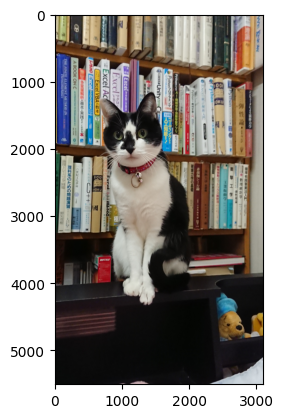

In [ ]:
from PIL import Image, ImageOps
from io import BytesIO
import requests
from matplotlib import pyplot as plt

# GitHub上の画像URL
image_github = "https://github.com/Taka-Lab-Python/Human_AI_Exercises/blob/main/cat2.png"
image_url = image_github.replace(
"github.com", "raw.githubusercontent.com").replace("/blob/", "/")

# GitHubから画像を取得
response = requests.get(image_url, timeout=30)
response.raise_for_status()

# PIL画像に変換
img_pil = Image.open(BytesIO(response.content))
img_pil = ImageOps.exif_transpose(img_pil)
img_pil = img_pil.convert("RGB")

print(f"画像のサイズ (幅, 高さ)ピクセル: {img_pil.size}")
plt.imshow(img_pil)  # 画像を描かせる
plt.show()

セル1：ライブラリのインストール

In [ ]:
# セル1：ライブラリのインストール
!pip install -q -U "transformers>=4.57.0" accelerate


セル2：モジュールのインポート(重要)


In [ ]:
#セル2：モジュールのインポート(重要)

import torch
from transformers import Qwen3VLForConditionalGeneration, AutoProcessor


セル3：モデルのダウンロード・読み込み


In [ ]:
# セル3：モデルのダウンロード・読み込み
MODEL_ID = "Qwen/Qwen3-VL-2B-Instruct"
# Hugging FaceからColabにダウンロード
model = Qwen3VLForConditionalGeneration.from_pretrained(
         MODEL_ID,
         dtype=torch.float16,
         device_map="cuda",
)
processor = AutoProcessor.from_pretrained(MODEL_ID)
model.eval()

print("モデルの読み込み完了")


config.json:   0%|          | 0.00/1.50k [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B / 4.26GB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/625 [00:00<?, ?it/s]

generation_config.json:   0%|          | 0.00/269 [00:00<?, ?B/s]

...

vocab.json:   0%|          | 0.00/2.78M [00:00<?, ?B/s]

merges.txt:   0%|          | 0.00/1.67M [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/7.03M [00:00<?, ?B/s]

video_preprocessor_config.json:   0%|          | 0.00/385 [00:00<?, ?B/s]

モデルの読み込み完了


セル4：写真のアップロード


Saving cat2.png to cat2 (6).png
画像のサイズ (幅, 高さ)ピクセル: (576, 1024)


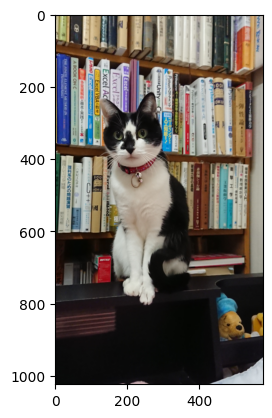

In [ ]:
from google.colab import files
from PIL import Image, ImageOps

uploaded = files.upload()
image_path = next(iter(uploaded))

img_pil = Image.open(image_path)
img_pil = ImageOps.exif_transpose(img_pil)   # スマホ写真の向きを補正
img_pil = img_pil.convert("RGB")
img_pil.thumbnail((1024, 1024))   # 大きな写真は縮小してメモリを節約

print(f"画像のサイズ (幅, 高さ)ピクセル: {img_pil.size}")
plt.imshow(img_pil)  # 画像を描かせる
plt.show()

セル5：プロンプトを入力して実行


In [ ]:
# セル5：プロンプトを入力して実行

prompt = "この写真に何が写っているか、背景も含め日本語で説明してください。"

messages = [
            {
                 "role": "user",
                 "content": [
                          {"type": "image", "image": img_pil},
                          {"type": "text", "text": prompt},
                      ],
              }
]

inputs = processor.apply_chat_template(
              messages,
              tokenize=True,
              add_generation_prompt=True,
              return_dict=True,
              return_tensors="pt",
             ).to(model.device)

# 推論モード：学習用の計算（勾配）を記録しないため、メモリ節約と高速化になる
with torch.inference_mode():
      generated_ids = model.generate(**inputs, max_new_tokens=500)

# generated_ids には「入力（プロンプト）＋回答」がつながって入っている
# 入力したトークン数を数える
input_length = inputs["input_ids"].shape[1]

# 入力の長さより後ろ＝モデルの回答部分だけを取り出す（画像は1枚なので [0]）
answer_ids = generated_ids[0][input_length:]

# トークン番号を日本語の文章に戻す（特殊トークンは除く）
answer = processor.decode(answer_ids, skip_special_tokens=True)

print(answer)


この写真は、書棚の上に座っている黒白の猫を写しています。背景には、多くの本が並んでおり、その中には「Excel VBA」「Python」「Unity」「理系のための問題演習」といったタイトルの本が見えます。猫は赤いネックレスを着ており、右下には小さなぬいぐるみが見えます。
